# Issue 16: Cast and Crew Feature Visualizations

Explore how cast and crew characteristics relate to movie popularity using features from `data\features\09_popularity_features.csv`

## 0. Setup

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

# Set up paths and output folder
file_path = r"data\features\09_popularity_features.csv"
output_dir = r"data\visualization"
os.makedirs(output_dir, exist_ok=True)

## 1. Import and Inspect Dataset

In [ ]:
#Importing and inspecting datasets #target_log_popularity 
df = pd.read_csv('../../data/features/09_popularity_features.csv') #target_log_popularity

print(df.shape)
print([c for c in df.columns if 'cast_size' in c or 'crew_size' in c])

#Inspecting 
cols = ['cast_size', 'crew_size', 'target_log_popularity']
print(df[cols].dtypes)
print(df[cols].isna().sum())
print((df[['cast_size', 'crew_size']] == 0).sum())
df[cols].describe()


(45430, 34)
['cast_size', 'crew_size']
cast_size                float64
crew_size                float64
target_log_popularity    float64
dtype: object
cast_size                1
crew_size                1
target_log_popularity    0
dtype: int64
cast_size    2414
crew_size     771
dtype: int64


,cast_size,crew_size,target_log_popularity
count,45429.000000,45429.000000,45430.000000
mean,12.371129,10.209470,0.978699
std,12.090133,15.805428,0.803990
min,0.000000,0.000000,0.000000
25%,6.000000,2.000000,0.326330
50%,10.000000,6.000000,0.754824
75%,15.000000,12.000000,1.542898
max,313.000000,435.000000,6.307166


In [ ]:
#Inspecting outliers
top = df.sort_values('cast_size', ascending=False).head(10)
top[['id', 'cast_size', 'crew_size', 'target_log_popularity']]

print(df['cast_size'].quantile([0.95, 0.99, 0.999]))
print(df['crew_size'].quantile([0.95, 0.99, 0.999]))

0.950     32.000
0.990     60.000
0.999    117.572
Name: cast_size, dtype: float64
0.950     33.0
0.990     85.0
0.999    155.0
Name: crew_size, dtype: float64


## 2. Create a scatter plot of `cast_size` vs. `target_log_popularity`.

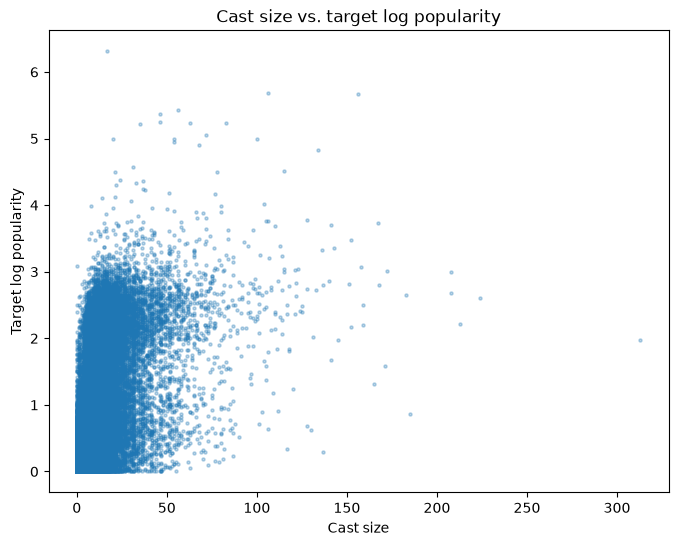

In [ ]:
# Cast size, full range
plt.figure(figsize=(8, 6))
plt.scatter(df['cast_size'], df['target_log_popularity'], s=5, alpha=0.3)
plt.xlabel('Cast size')
plt.ylabel('Target log popularity')
plt.title('Cast size vs. target log popularity')
plt.show()

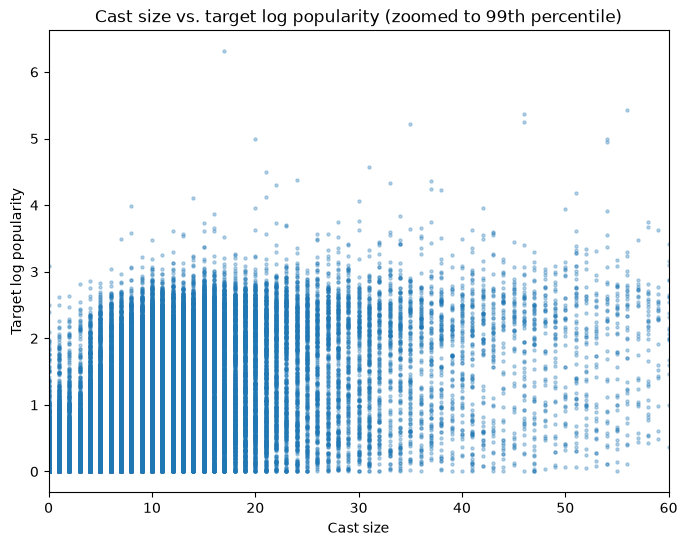

In [ ]:
# Cast size, zoomed to the 99th percentile
plt.figure(figsize=(8, 6))
plt.scatter(df['cast_size'], df['target_log_popularity'], s=5, alpha=0.3)
plt.xlim(0, df['cast_size'].quantile(0.99))
plt.xlabel('Cast size')
plt.ylabel('Target log popularity')
plt.title('Cast size vs. target log popularity (zoomed to 99th percentile)')
plt.show()


## 3. Create a scatter plot of `crew_size` vs. `target_log_popularity`.

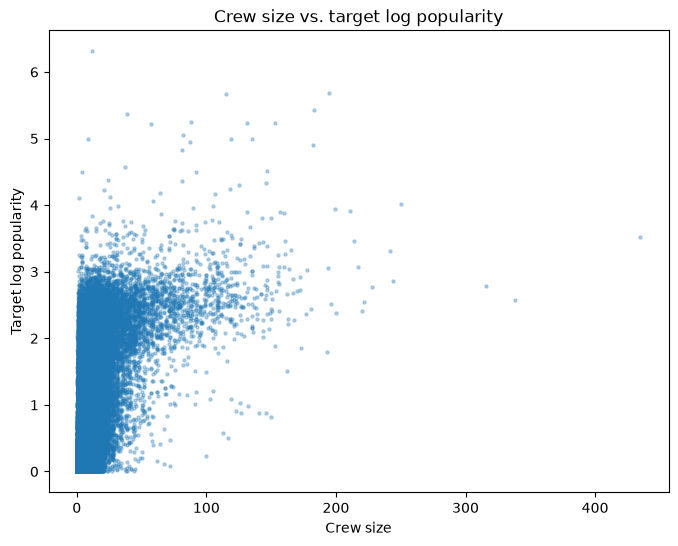

In [ ]:
# Crew size, full range
plt.figure(figsize=(8, 6))
plt.scatter(df['crew_size'], df['target_log_popularity'], s=5, alpha=0.3)
plt.xlabel('Crew size')
plt.ylabel('Target log popularity')
plt.title('Crew size vs. target log popularity')
plt.show()

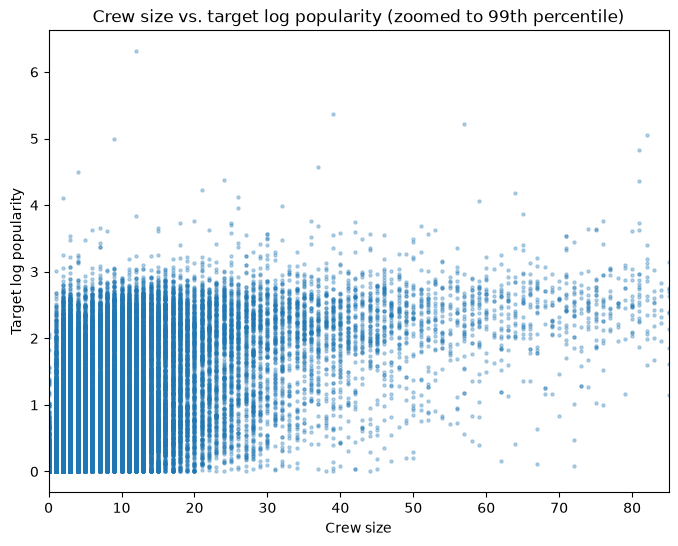

In [ ]:
# Crew size, zoomed to the 99th percentile
plt.figure(figsize=(8, 6))
plt.scatter(df['crew_size'], df['target_log_popularity'], s=5, alpha=0.3)
plt.xlim(0, df['crew_size'].quantile(0.99))
plt.xlabel('Crew size')
plt.ylabel('Target log popularity')
plt.title('Crew size vs. target log popularity (zoomed to 99th percentile)')
plt.show()


## 4. Create a box plot comparing `target_log_popularity` for movies with and without a director (`has_director`).

In [ ]:
# Remove rows with missing values before creating plots.
plot_data = df.dropna(subset=["has_director", "cast_size", "crew_size", "target_log_popularity"])

has_director = plot_data["has_director"].astype(bool)
without_director = plot_data.loc[~has_director, "target_log_popularity"]
with_director = plot_data.loc[has_director, "target_log_popularity"]

plt.figure(figsize=(8, 6))
plt.boxplot([without_director, with_director],showfliers=True)
plt.xticks([1, 2], ["No Director", "Has Director"])
plt.xlabel("Director information")
plt.ylabel("Target log popularity")
plt.title("Movie Popularity With and Without a Director")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "popularity_by_director.png"), dpi=300)
plt.show()

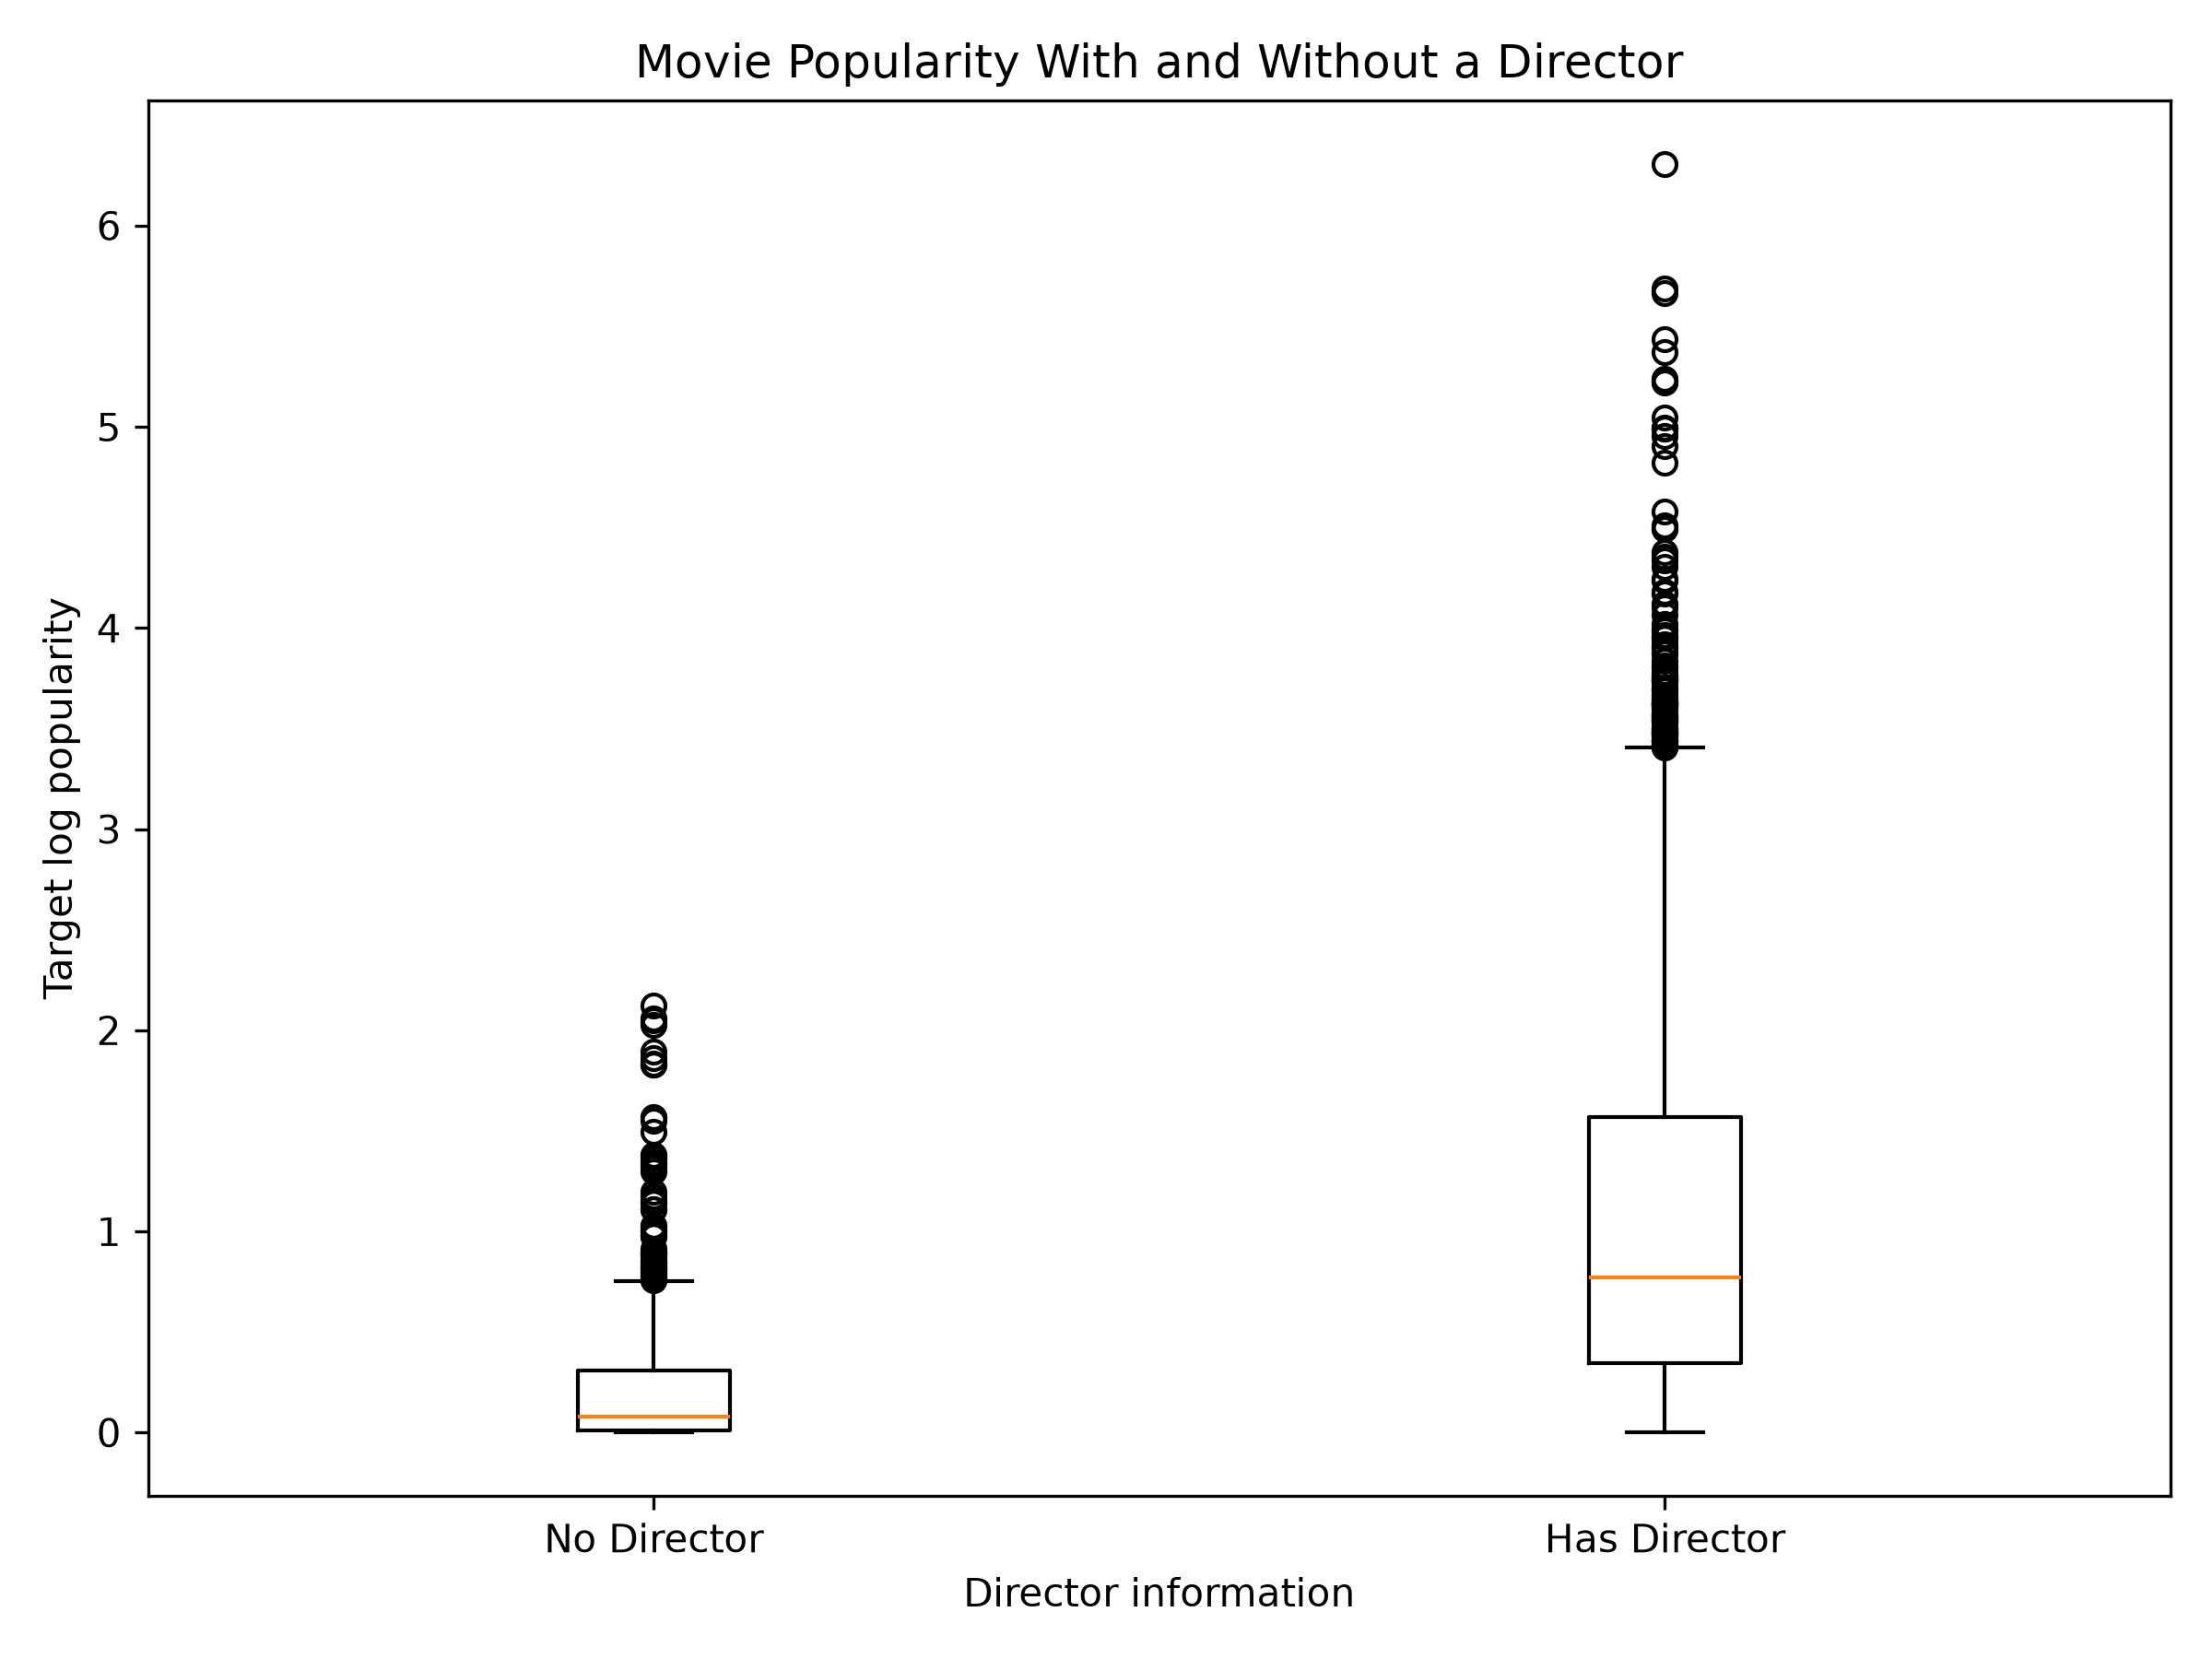

## 5. Create a scatter plot of `cast_size` vs. `crew_size`, colored by `target_log_popularity`.

In [ ]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(plot_data["cast_size"], plot_data["crew_size"], c=plot_data["target_log_popularity"], cmap="viridis", s=12, alpha=0.6)

plt.colorbar(scatter, label="Target log popularity")
plt.xlabel("Cast size")
plt.ylabel("Crew size")
plt.title("Cast Size vs. Crew Size Colored by Movie Popularity")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "cast_vs_crew_popularity.png"), dpi=300)
plt.show()

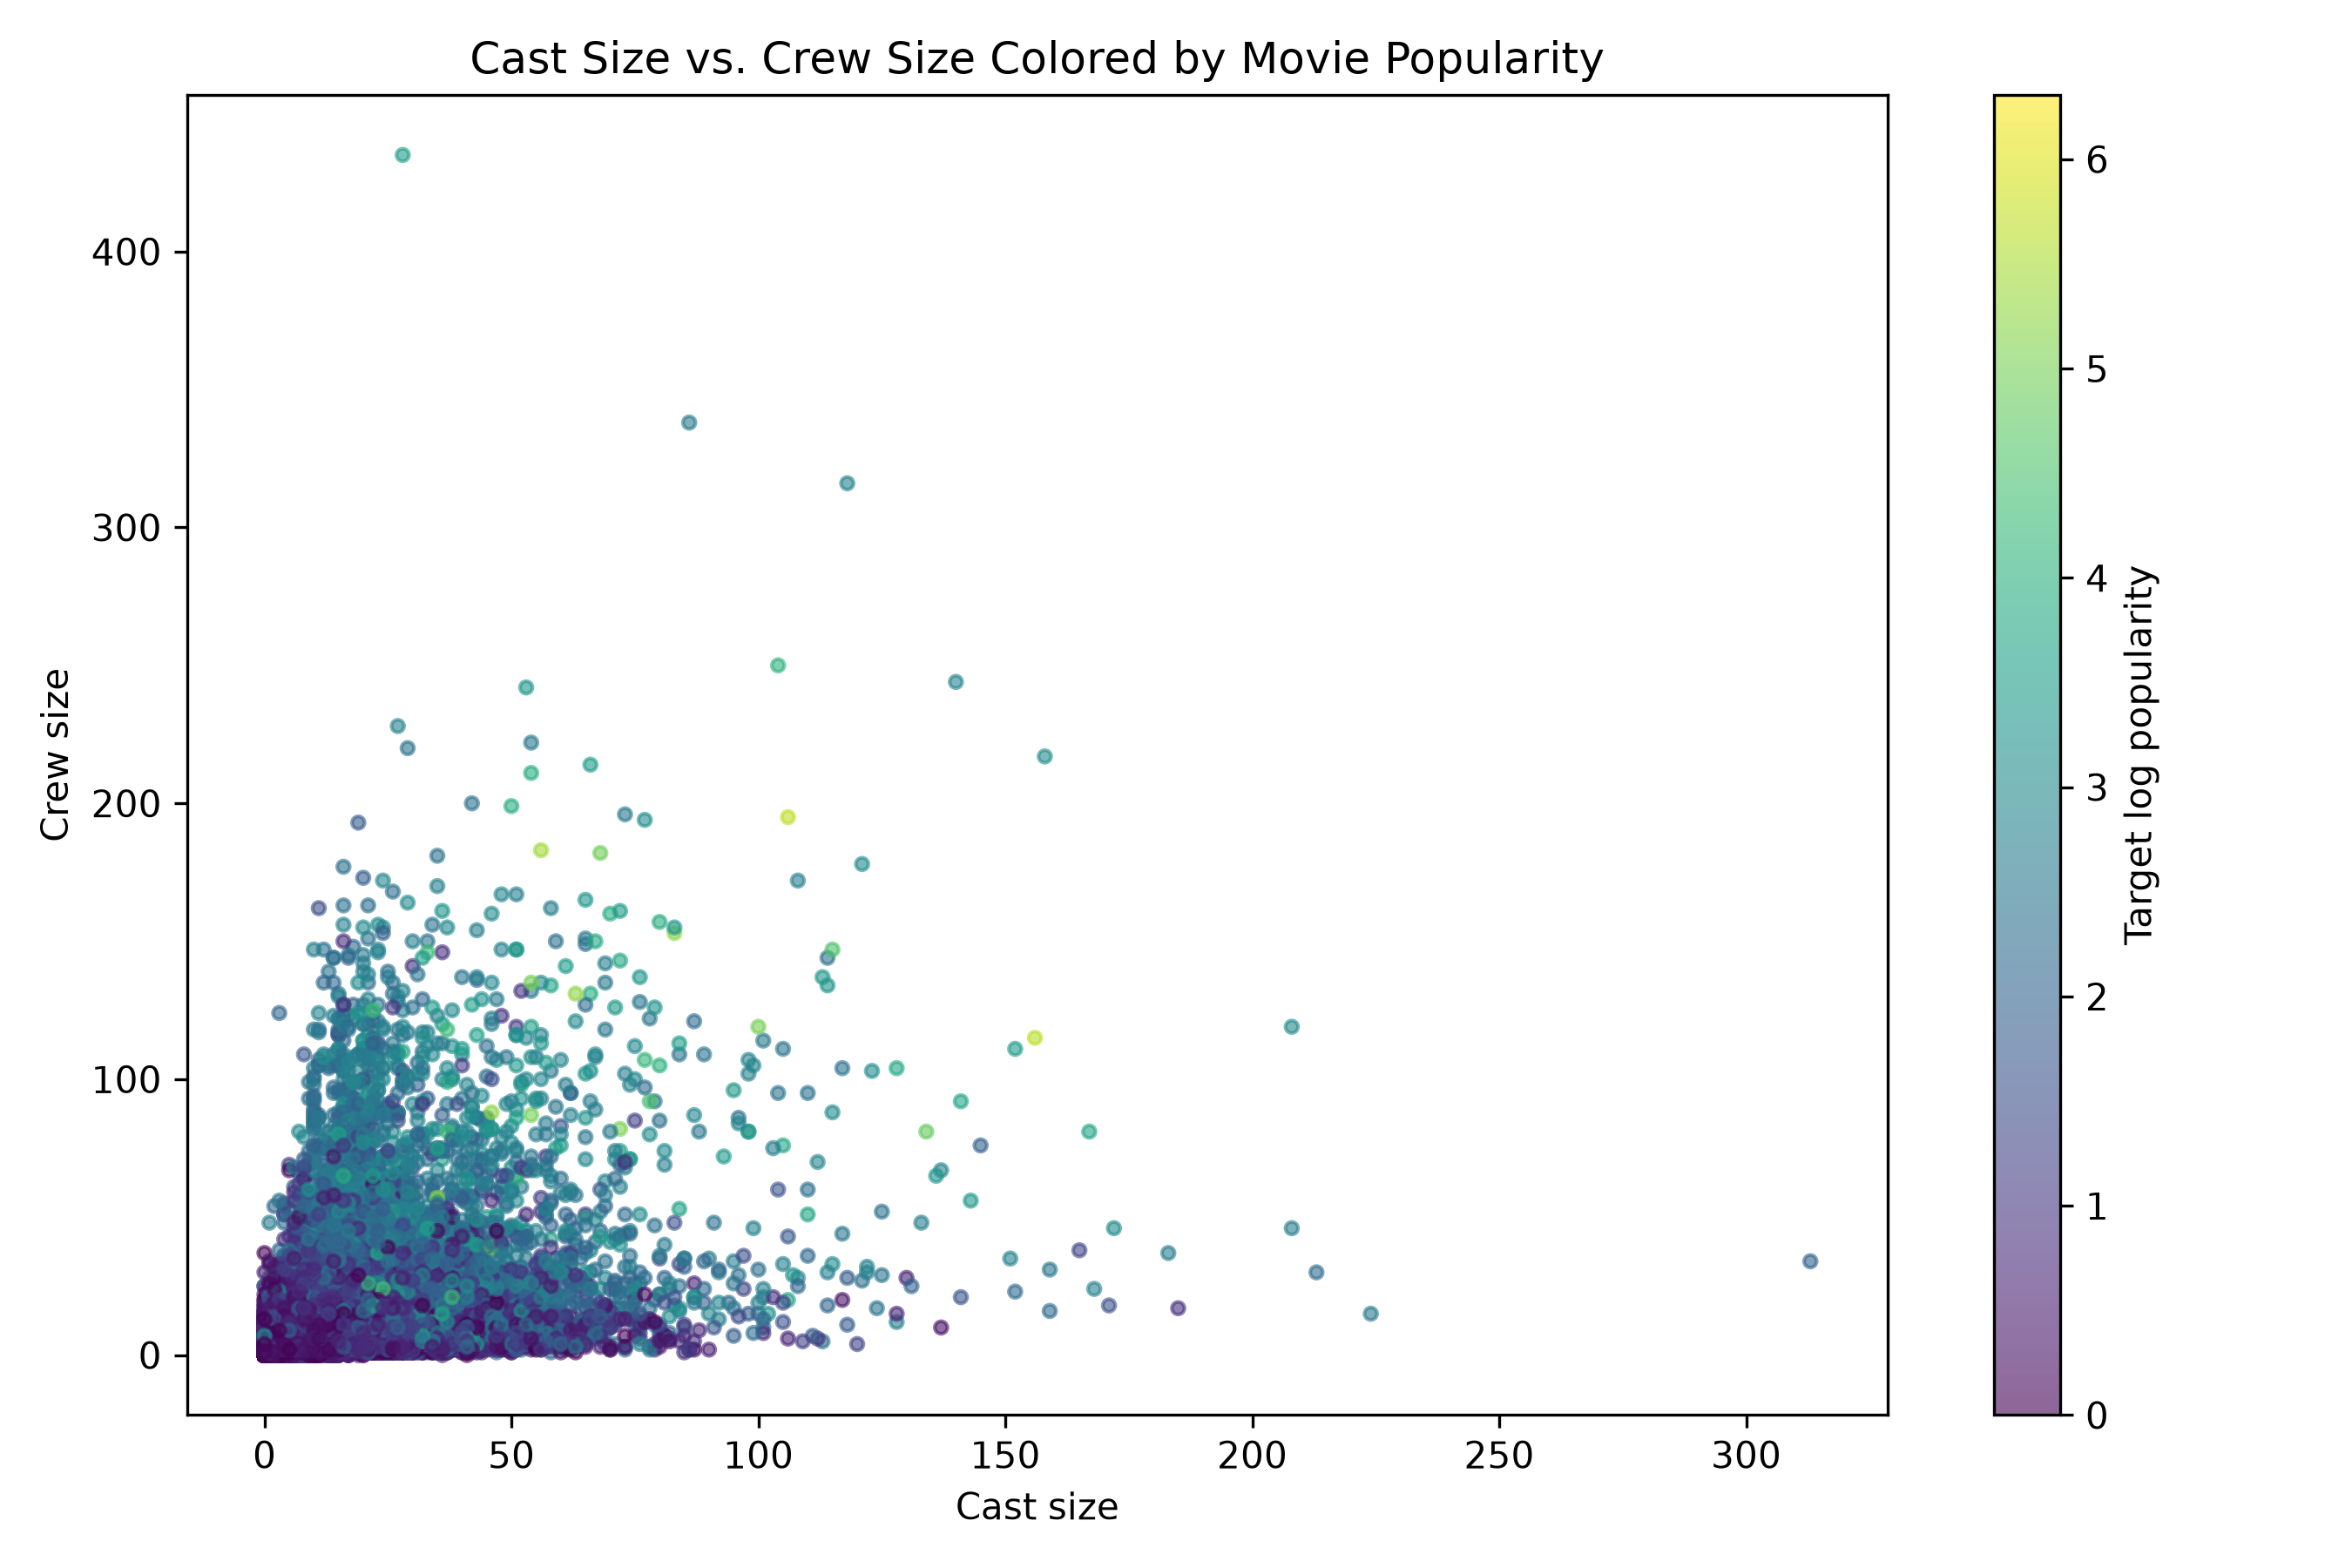

## 6. Create a correlation heatmap for `cast_size`, `crew_size`, `has_director`, and `target_log_popularity`.

In [ ]:
correlation_columns = ["cast_size", "crew_size", "has_director", "target_log_popularity"]

correlation_data = df[correlation_columns].dropna().copy()
# Convert has_director to numeric values if it is stored as True/False.
correlation_data["has_director"] = (correlation_data["has_director"].astype(int))

# Calculate the correlation matrix.
correlation_matrix = correlation_data.corr()

# Create the heatmap.
plt.figure(figsize=(8, 6))
heatmap = plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(heatmap, label="Correlation")
plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right",
)
plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)
plt.title("Correlation Heatmap of Movie Features")

# Add the correlation value to each cell.
for row in range(len(correlation_columns)):
    for column in range(len(correlation_columns)):
        value = correlation_matrix.iloc[row, column]
        plt.text(column, row, f"{value:.2f}", ha="center", va="center", color="black")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "correlation_heatmap.png"), dpi=300)
plt.show()

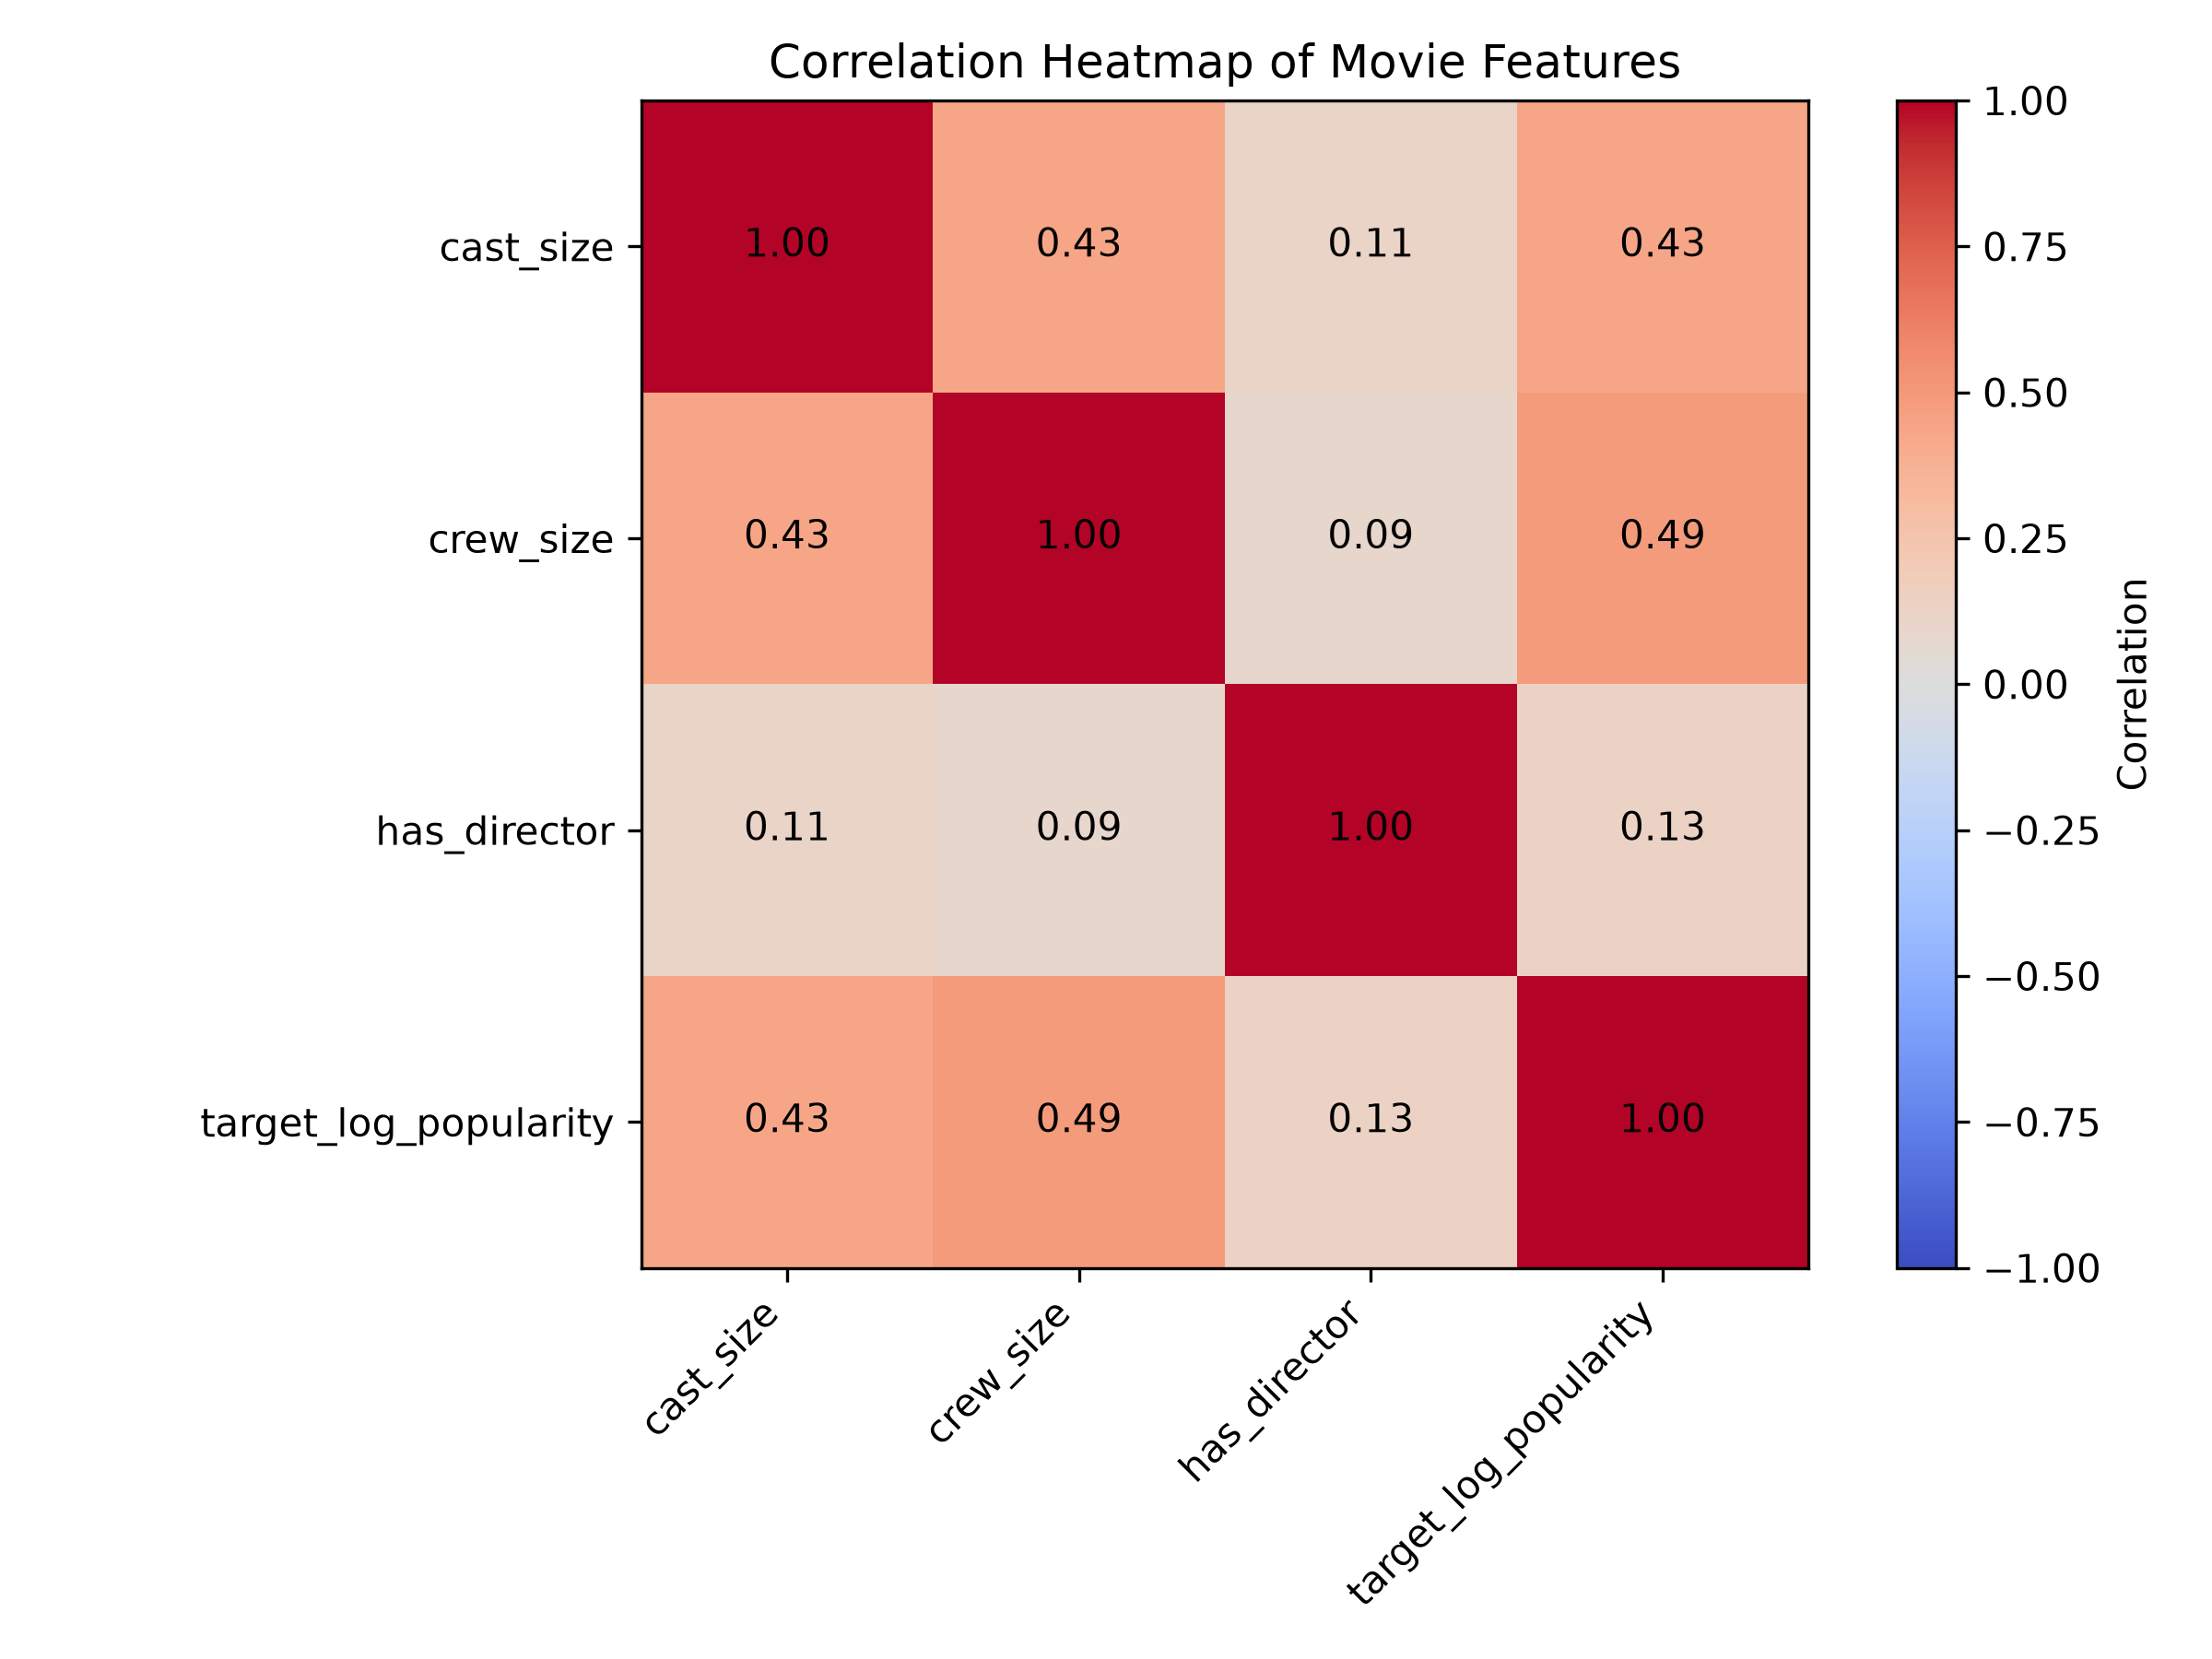

## Results

7 data visualization graphs output to `data\visualization`:  
1. Scatter plot of `cast_size` vs. `target_log_popularity`.   
    - (`data\visualization\cast_size_vs_popularity.png`)  
2. Additional version zoomed to the 99th percentile.  
    - (`data\visualization\cast_size_vs_popularity_zoomed.png`)  
3. Scatter plot of `crew_size` vs. `target_log_popularity`.  
    - (`data\visualization\crew_size_vs_popularity.png`)  
4. Additional version zoomed to the 99th percentile.  
    - (`data\visualization\crew_size_vs_popularity_zoomed.png`)  
5. Box plot comparing `target_log_popularity` for movies with and without a director (`has_director`).  
    - (`data\visualization\popularity_by_director.png`)  
6. Scatter plot of `cast_size` vs. `crew_size`, colored by `target_log_popularity`.  
    - (`data\visualization\cast_vs_crew_popularity.png`)  
7. Correlation heatmap for `cast_size`, `crew_size`, `has_director`, and `target_log_popularity`.  
    - (`data\visualization\correlation_heatmap.png`)  